# AI-Based Route Planning for a Warehouse Delivery Robot
**Name:** Akshat Jain  **Roll No:** BT23CSD020  **Course:** Artificial Intelligence – Coding Assignment

A robot carries packages from the packing station **S** to the dispatch area **G** on a 2D warehouse grid. We compare **BFS, DFS, Greedy Best-First Search and A\*** on the same grid, and show how the robot detects a trolley that is not on its map and **replans** with A\*.

## 1. Import libraries
Only the Python standard library is used for the search. Matplotlib is used for the grid pictures and animations.

In [1]:
import heapq, time, os, sys
from collections import deque
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
try:
    from IPython.display import HTML, display
except ImportError:                                # running as a plain script
    pass

IN_NOTEBOOK = 'ipykernel' in sys.modules
os.makedirs('outputs', exist_ok=True)

def show(fig, name):
    # save every figure to outputs/ (for the README) and show it in the notebook
    fig.savefig(f'outputs/{name}.png', dpi=120, bbox_inches='tight')
    plt.show() if IN_NOTEBOOK else plt.close(fig)

## 2. Task 1 – Warehouse environment
| Symbol | Cell | Cost to enter |
|---|---|---|
| `.` | open aisle | 1 |
| `C` | crowded aisle | 4 |
| `#` | shelf | blocked |
| `X` | restricted zone | blocked |
| `S` / `G` | packing station (start) / dispatch area (goal) | 1 |

The layout has three horizontal aisles (top, middle, bottom) joined by cross-aisles at the left, centre and right. The **middle aisle is crowded**: it is the shortest way to the goal but expensive. The top aisle is longer but every cell costs 1. Part of the bottom aisle is a restricted zone.

In [2]:
WAREHOUSE = [
    "..##################",
    "....................",
    "..########.#######..",
    "..########.#######..",
    "..########.#######..",
    "S.CCCCCCCCCCCCCCCC.G",
    "..########.#######..",
    "..########.#######..",
    "..XXX#####.#######..",
    "..XXX...........CC..",
    "..##################",
]
COST = {'.': 1, 'C': 4, 'S': 1, 'G': 1}          # cells not in COST (#, X, T) are impassable
ROWS, COLS = len(WAREHOUSE), len(WAREHOUSE[0])
GRID = [list(row) for row in WAREHOUSE]

def find(ch):
    return next((r, c) for r in range(ROWS) for c in range(COLS) if GRID[r][c] == ch)

START, GOAL = find('S'), find('G')
print(f'Grid size: {ROWS} x {COLS} | start {START} | goal {GOAL}')
for row in WAREHOUSE:
    print(' '.join(row))

Grid size: 11 x 20 | start (5, 0) | goal (5, 19)
. . # # # # # # # # # # # # # # # # # #
. . . . . . . . . . . . . . . . . . . .
. . # # # # # # # # . # # # # # # # . .
. . # # # # # # # # . # # # # # # # . .
. . # # # # # # # # . # # # # # # # . .
S . C C C C C C C C C C C C C C C C . G
. . # # # # # # # # . # # # # # # # . .
. . # # # # # # # # . # # # # # # # . .
. . X X X # # # # # . # # # # # # # . .
. . X X X . . . . . . . . . . . C C . .
. . # # # # # # # # # # # # # # # # # #


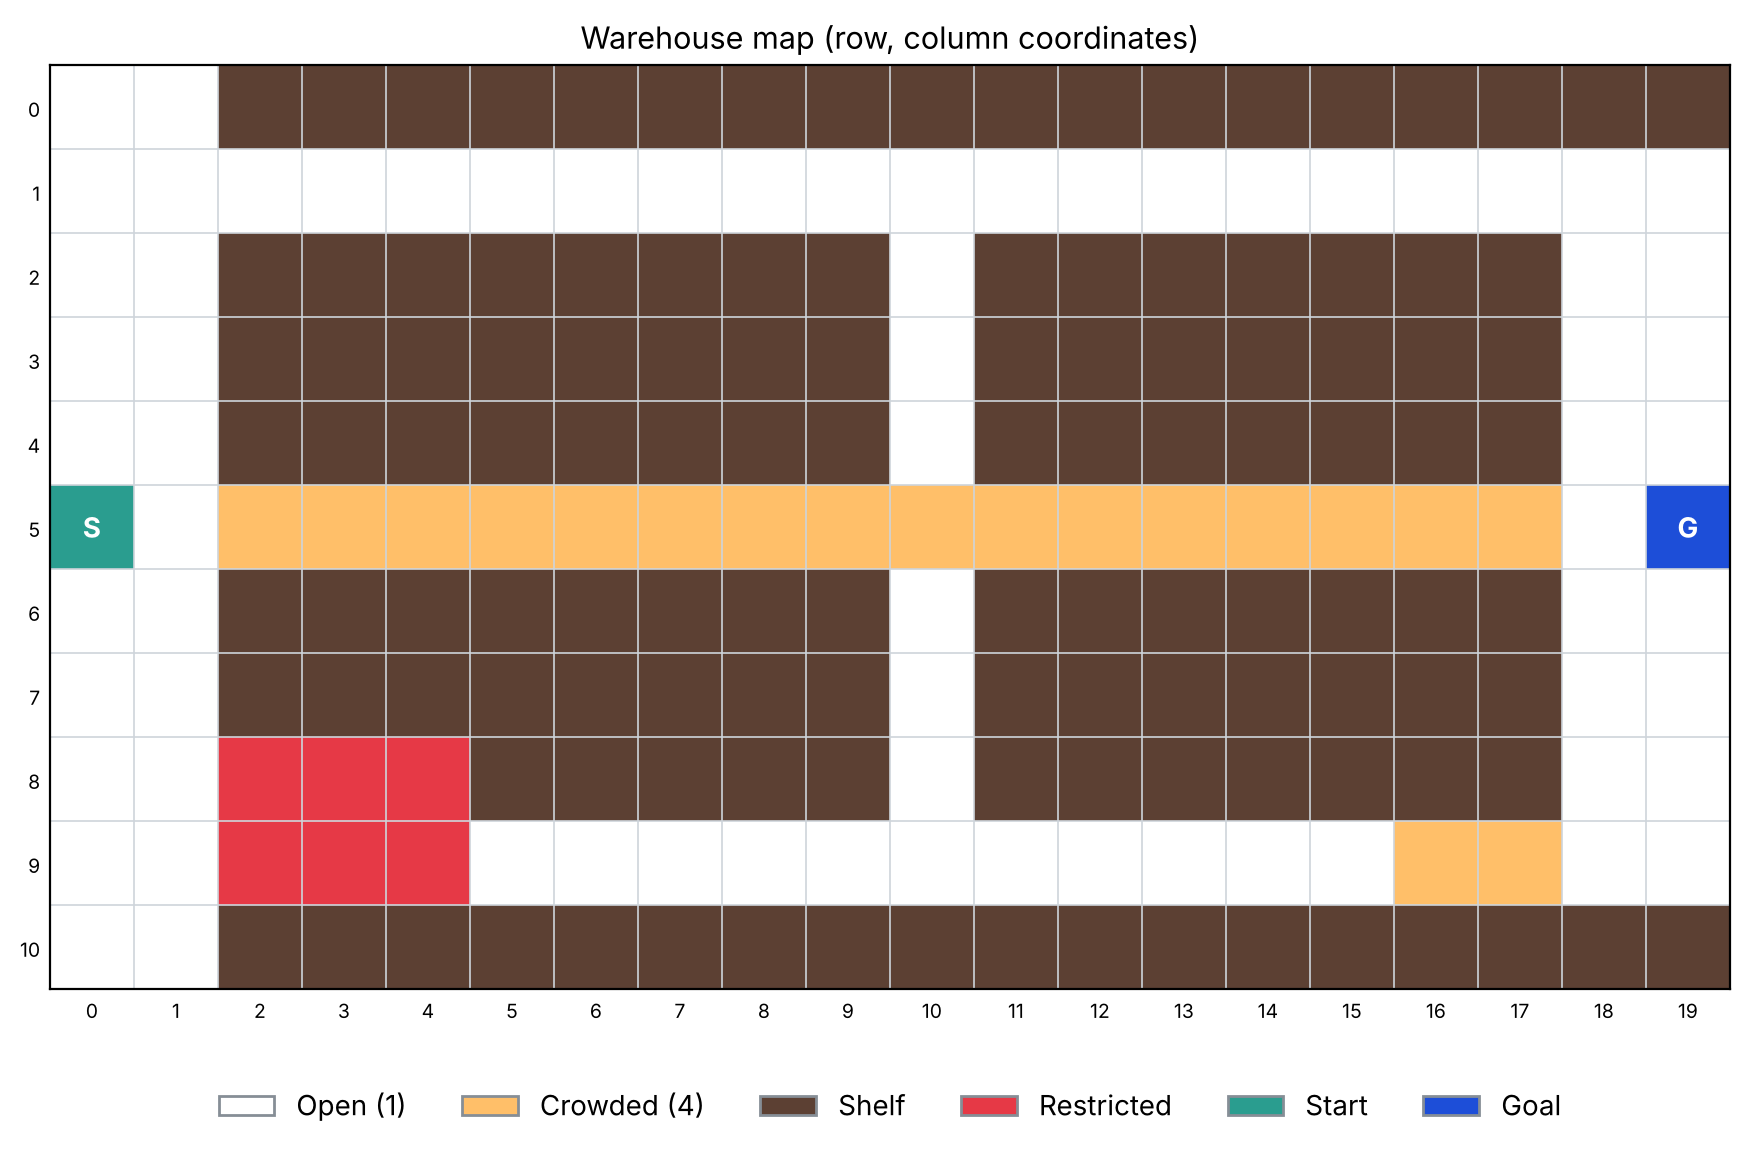

In [3]:
CODES = {'.': 0, 'C': 1, '#': 2, 'X': 3, 'S': 4, 'G': 5, 'T': 6}
CMAP = ListedColormap(['#ffffff', '#ffbf69', '#5c4033', '#e63946', '#2a9d8f', '#1d4ed8', '#7b2cbf'])
LEGEND = [Patch(facecolor=c, edgecolor='#868e96', label=l) for c, l in zip(CMAP.colors, ['Open (1)', 'Crowded (4)', 'Shelf', 'Restricted',
                                                              'Start', 'Goal', 'Trolley'])]

def draw(ax, grid, path=None, explored=None, robot=None, title='', path_color='#1d4ed8', style='-'):
    ax.imshow([[CODES[ch] for ch in row] for row in grid], cmap=CMAP, vmin=0, vmax=6)
    if explored:                                   # cells the algorithm expanded
        er, ec = zip(*explored)
        ax.scatter(ec, er, s=18, color='#adb5bd', zorder=2)
    if path:
        pr, pc = zip(*path)
        ax.plot(pc, pr, style, color=path_color, linewidth=3, zorder=3)
    if robot:
        ax.plot(robot[1], robot[0], 'o', color='black', markersize=13, zorder=4)
    for (r, c), ch in [(START, 'S'), (GOAL, 'G')] + [((r, c), 'T') for r in range(ROWS) for c in range(COLS) if grid[r][c] == 'T']:
        ax.text(c, r, ch, ha='center', va='center', color='white', fontweight='bold', zorder=5)
    ax.set_xticks(range(COLS)); ax.set_yticks(range(ROWS))
    ax.set_xticks([x - .5 for x in range(1, COLS)], minor=True); ax.set_yticks([y - .5 for y in range(1, ROWS)], minor=True)
    ax.grid(which='minor', color='#ced4da', linewidth=0.6); ax.tick_params(which='both', length=0, labelsize=7)
    ax.set_title(title, fontsize=11)

fig, ax = plt.subplots(figsize=(11, 6))
draw(ax, GRID, title='Warehouse map (row, column coordinates)')
ax.legend(handles=LEGEND[:6], loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=6, frameon=False)
show(fig, '1_warehouse_grid')

## 3. Task 2 – Problem formulation
| Component | Definition |
|---|---|
| **State** | the robot's cell `(row, col)` |
| **Initial state** | the packing station `S` = (5, 0) |
| **Actions** | Up, Down, Left, Right (only into cells inside the grid that are not a shelf, restricted zone or trolley) |
| **Transition model** | `Result((r, c), Up) = (r-1, c)`, Down = `(r+1, c)`, Left = `(r, c-1)`, Right = `(r, c+1)` |
| **Goal test** | state == dispatch area `G` = (5, 19) |
| **Path cost** | sum of the cost of every cell entered: 1 for an open cell, 4 for a crowded cell |

In [4]:
ACTIONS = {'Up': (-1, 0), 'Down': (1, 0), 'Left': (0, -1), 'Right': (0, 1)}

def actions(grid, state):
    r, c = state
    for name, (dr, dc) in ACTIONS.items():
        nr, nc = r + dr, c + dc
        if 0 <= nr < ROWS and 0 <= nc < COLS and grid[nr][nc] in COST:
            yield name, (nr, nc)                      # (action, resulting state)

def step_cost(grid, state):
    return COST[grid[state[0]][state[1]]]

def path_cost(grid, path):
    return sum(step_cost(grid, s) for s in path[1:])

def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

print('Actions from start:', [a for a, _ in actions(GRID, START)])
print('Manhattan distance start -> goal:', manhattan(START, GOAL))

Actions from start: ['Up', 'Down', 'Right']
Manhattan distance start -> goal: 19


## 4. Task 3 – Search algorithms
All four use the same `search` function; only the frontier changes:

| Algorithm | Frontier | Picks next | Optimal? |
|---|---|---|---|
| **BFS** | FIFO queue | the oldest node (fewest moves) | fewest **moves**, not lowest cost |
| **DFS** | LIFO stack | the newest node (goes deep first) | no |
| **Greedy Best-First** | priority queue on `h(n)` | the node that looks closest to the goal | no |
| **A\*** | priority queue on `f(n) = g(n) + h(n)` | lowest cost so far + estimate | **yes**, lowest cost |

All four are graph searches (a cell is expanded at most once) and the goal test is done when a node is expanded, so "nodes expanded" is counted the same way for each.

**Why Manhattan distance is a lower bound:** the robot moves one cell at a time, only up, down, left or right, so it needs at least |Δrow| + |Δcol| moves to reach the goal, and every move costs at least 1. Shelves, crowded cells and detours can only make the real cost larger, never smaller. So h(n) never overestimates (it is **admissible**), and A\* returns the lowest-cost route.

In [5]:
def search(grid, algorithm, start=START, goal=GOAL):
    t0 = time.perf_counter()
    g = {start: 0}
    parent = {start: None}
    expanded, order = set(), []
    tie = 0
    if algorithm == 'BFS':
        frontier = deque([start])
    elif algorithm == 'DFS':
        frontier = [start]
    else:
        frontier = [(manhattan(start, goal), 0, start)]

    while frontier:
        if algorithm == 'BFS':
            state = frontier.popleft()
        elif algorithm == 'DFS':
            state = frontier.pop()
        else:
            state = heapq.heappop(frontier)[2]
        if state in expanded:
            continue
        expanded.add(state); order.append(state)

        if state == goal:                               # goal test on expansion
            path = []
            while state is not None:
                path.append(state)
                state = parent[state]
            path.reverse()
            return dict(algorithm=algorithm, found=True, path=path, moves=len(path) - 1,
                        cost=path_cost(grid, path), expanded=len(order), explored=order,
                        time_ms=(time.perf_counter() - t0) * 1000)

        children = list(actions(grid, state))
        if algorithm == 'DFS':
            children.reverse()                          # so Up is explored first, then Down, Left, Right
        for _, child in children:
            new_g = g[state] + step_cost(grid, child)
            if algorithm in ('BFS', 'DFS', 'Greedy'):
                if algorithm == 'DFS' and child not in expanded:
                    parent[child], g[child] = state, new_g
                    frontier.append(child)
                elif child not in parent:
                    parent[child], g[child] = state, new_g
                    if algorithm == 'BFS':
                        frontier.append(child)
                    else:
                        tie += 1
                        heapq.heappush(frontier, (manhattan(child, goal), tie, child))
            elif new_g < g.get(child, float('inf')):    # A*: keep the cheapest path to each cell
                parent[child], g[child] = state, new_g
                tie += 1
                heapq.heappush(frontier, (new_g + manhattan(child, goal), tie, child))

    return dict(algorithm=algorithm, found=False, path=None, moves=None, cost=None,
                expanded=len(order), explored=order, time_ms=(time.perf_counter() - t0) * 1000)

ALGORITHMS = ['BFS', 'DFS', 'Greedy', 'A*']
results = {a: search(GRID, a) for a in ALGORITHMS}
for a, r in results.items():
    if r['found']:
        print(f"{a:7} route found: {r['moves']} moves, cost {r['cost']}, {r['expanded']} nodes expanded")
    else:
        print(f'{a:7} NO ROUTE FOUND')

BFS     route found: 19 moves, cost 67, 73 nodes expanded
DFS     route found: 45 moves, cost 72, 80 nodes expanded
Greedy  route found: 19 moves, cost 67, 20 nodes expanded
A*      route found: 27 moves, cost 27, 49 nodes expanded


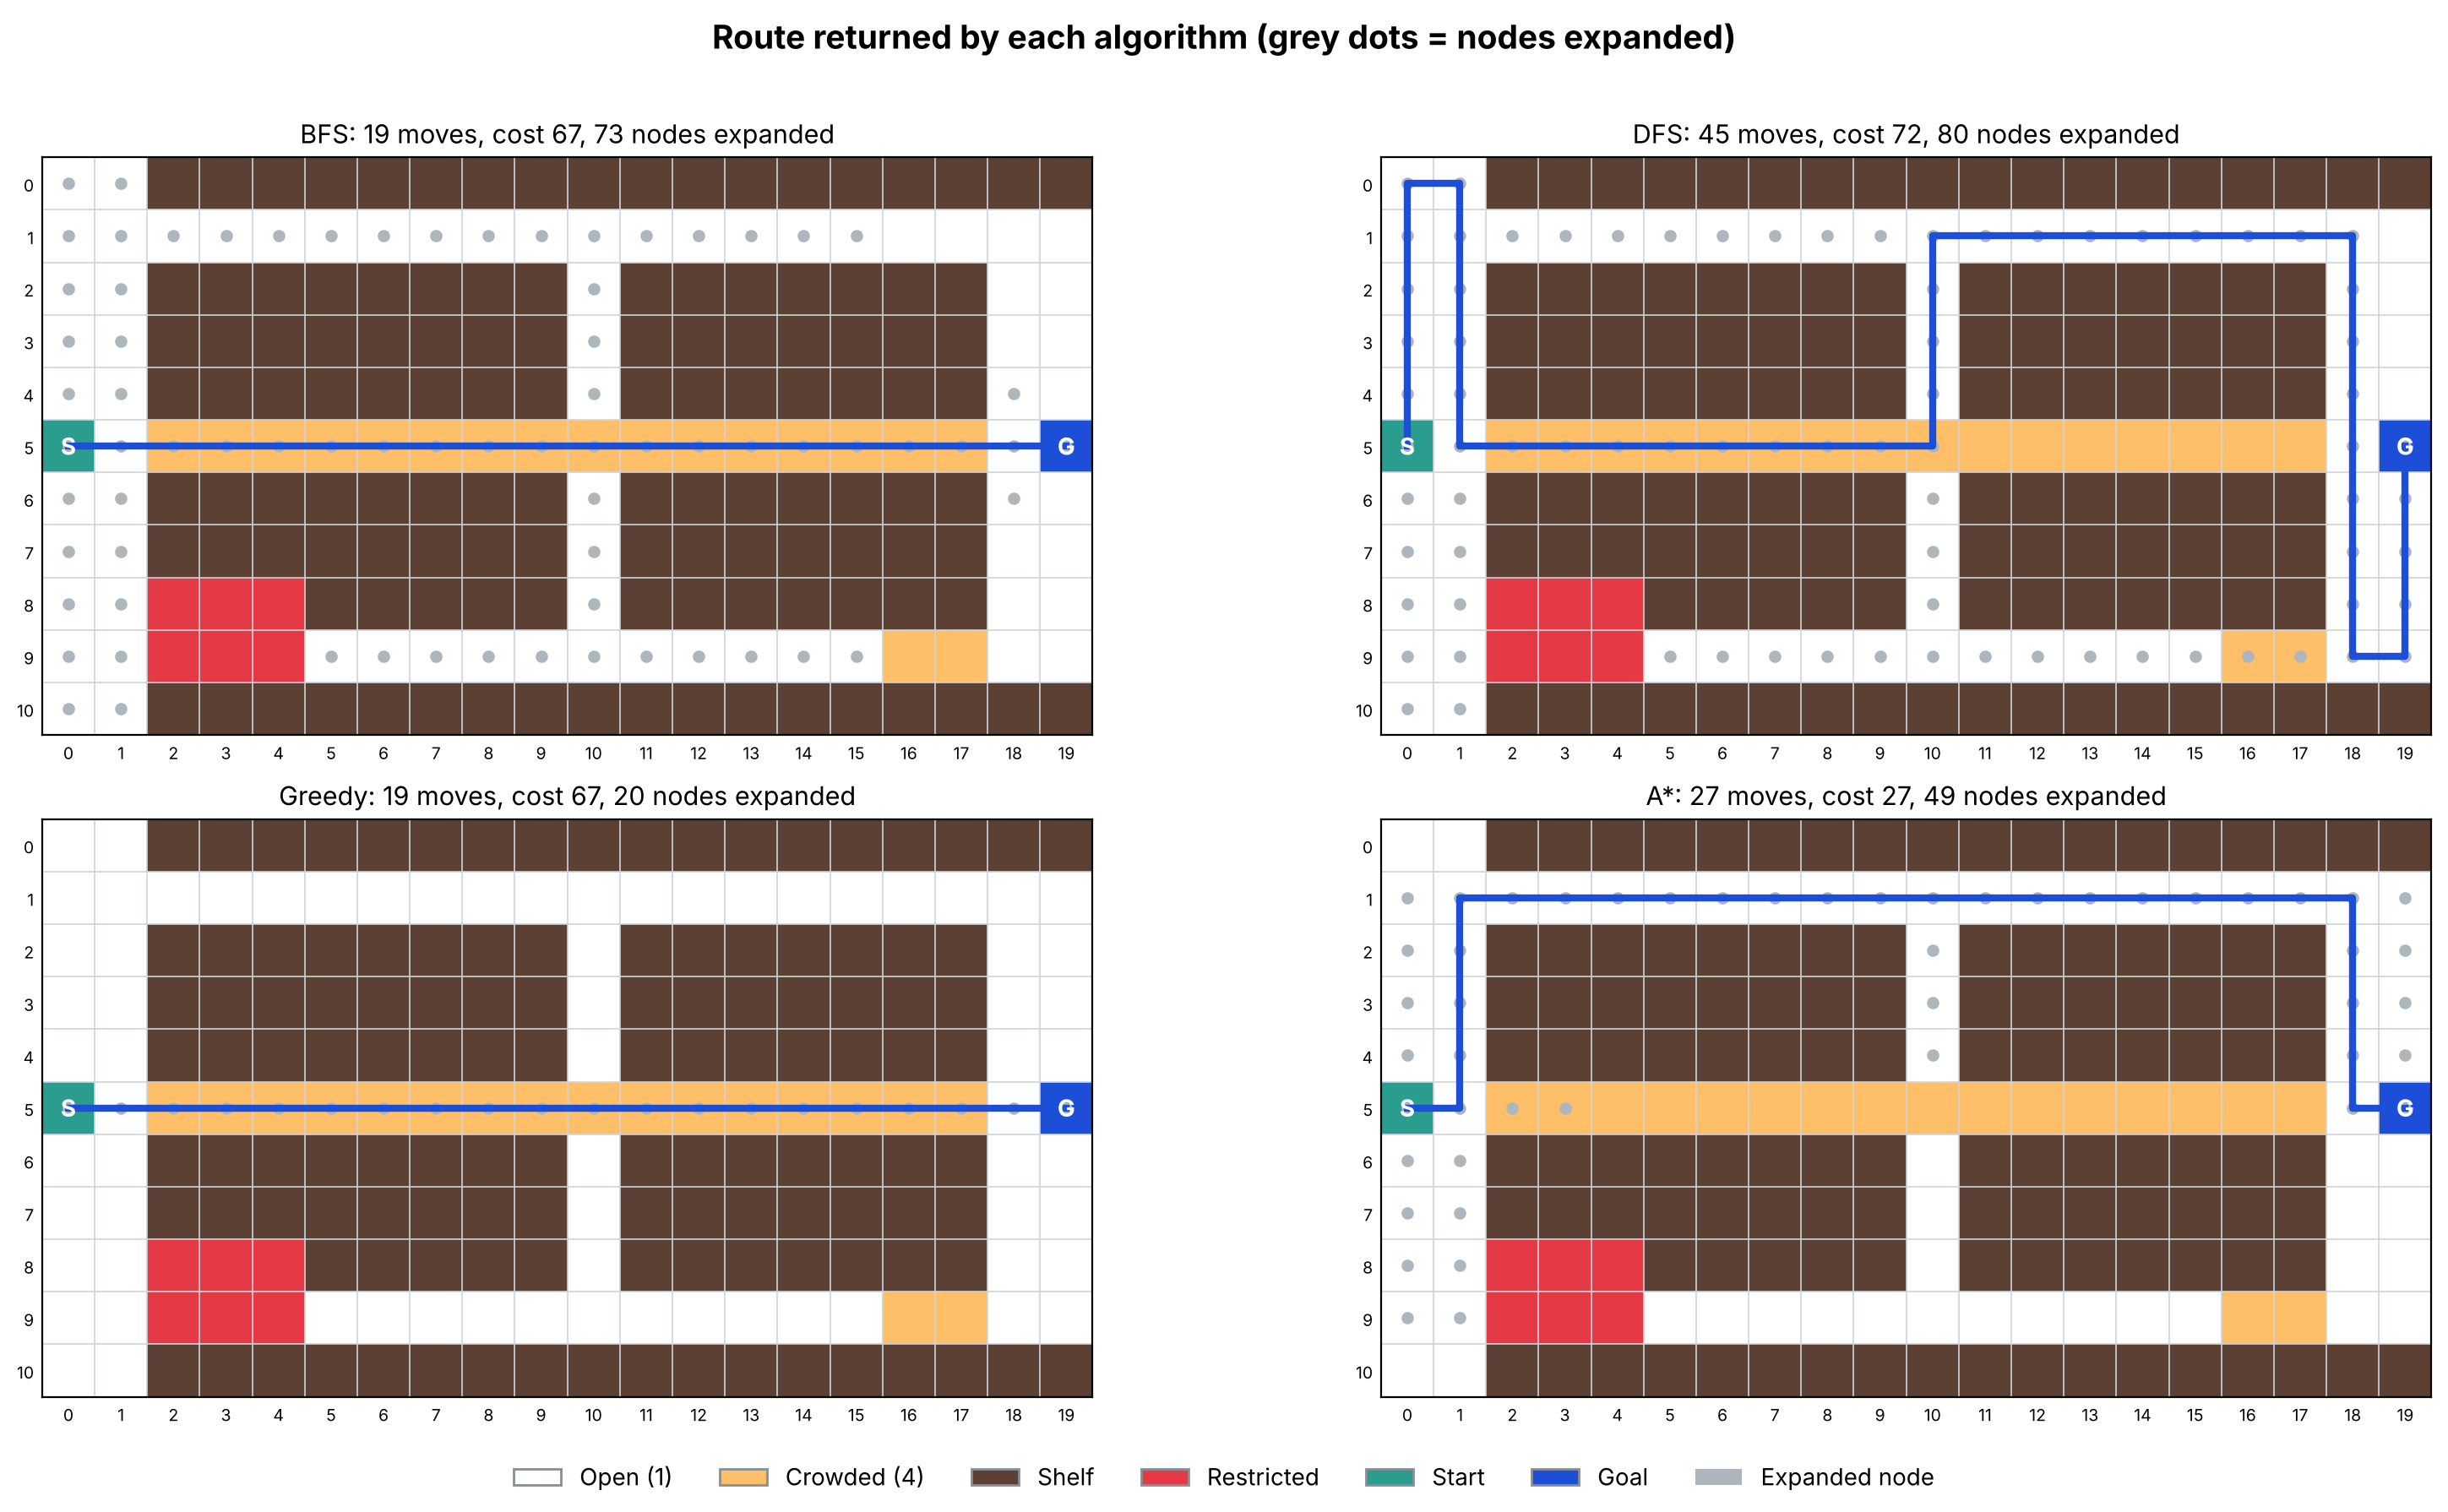

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, a in zip(axes.flat, ALGORITHMS):
    r = results[a]
    title = (f"{a}: {r['moves']} moves, cost {r['cost']}, {r['expanded']} nodes expanded" if r['found']
             else f'{a}: NO ROUTE FOUND')
    draw(ax, GRID, path=r['path'], explored=r['explored'], title=title)
fig.legend(handles=LEGEND[:6] + [Patch(facecolor='#adb5bd', label='Expanded node')], loc='lower center', ncol=7, frameon=False)
fig.suptitle('Route returned by each algorithm (grey dots = nodes expanded)', fontsize=14, fontweight='bold')
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
show(fig, '2_algorithm_routes')

### Short crowded route vs longer cheaper route
The direct middle aisle is only 19 moves but crosses 16 crowded cells. The top aisle needs 27 moves, but every cell costs 1.

In [7]:
def route_through(row):
    # a hand-built route that stays in one horizontal aisle, used only to compare the two options
    path = [START]
    r, c = START
    while r != row:
        r += 1 if row > r else -1; path.append((r, c))
    while c != GOAL[1]:
        c += 1; path.append((r, c))
    while r != GOAL[0]:
        r += 1 if GOAL[0] > r else -1; path.append((r, c))
    return path

for name, row in [('Short, crowded (middle aisle)', 5), ('Longer, open (top aisle)', 1)]:
    p = route_through(row)
    print(f'{name:31}: {len(p) - 1:2} moves, cost {path_cost(GRID, p)}')
print()
print(f"BFS chose  : {results['BFS']['moves']} moves, cost {results['BFS']['cost']}  -> fewest moves")
print(f"A* chose   : {results['A*']['moves']} moves, cost {results['A*']['cost']}  -> lowest cost")

Short, crowded (middle aisle)  : 19 moves, cost 67
Longer, open (top aisle)       : 27 moves, cost 27

BFS chose  : 19 moves, cost 67  -> fewest moves
A* chose   : 27 moves, cost 27  -> lowest cost


### Clear message when no route exists
If shelves or trolleys cut every aisle, each algorithm reports that no route was found.

In [8]:
sealed = [row[:] for row in GRID]
for r in (1, 5, 9):
    sealed[r][12] = 'T'                                 # block all three aisles at column 12
for a in ALGORITHMS:
    r = search(sealed, a)
    print(f'{a:7}:', 'route found' if r['found'] else f"NO ROUTE FOUND (searched {r['expanded']} reachable cells)")

BFS    : NO ROUTE FOUND (searched 55 reachable cells)
DFS    : NO ROUTE FOUND (searched 55 reachable cells)
Greedy : NO ROUTE FOUND (searched 55 reachable cells)
A*     : NO ROUTE FOUND (searched 55 reachable cells)


## 5. Task 4 – Trolley detection and replanning
- The robot plans with A\* on its **known map**, which does not contain the trolley.
- The **real warehouse** has a trolley on that planned route.
- At every step the robot's sensor checks the **next cell** on its route **before entering it**. If a trolley is there, the robot marks it on its known map and **replans with A\* from its current position**.
- If A\* finds no route on the updated map, the robot stops and reports that no alternative exists.

In [9]:
def run_robot(real_grid, known_grid, start=START, goal=GOAL):
    known = [row[:] for row in known_grid]
    pos, plan = start, search(known, 'A*', start, goal)
    log = dict(walked=[start], plans=[plan['path']], replans=0, nodes=plan['expanded'], detections=[],
               events=[], frames=[(start, plan['path'], [row[:] for row in known], 'Initial A* plan', 1)])
    if not plan['found']:
        log['events'].append('No route on the known map'); return log, False
    path, i = plan['path'], 0
    while pos != goal:
        nxt = path[i + 1]
        if real_grid[nxt[0]][nxt[1]] == 'T':               # sensor: obstacle in the next cell
            known[nxt[0]][nxt[1]] = 'T'                     # update the robot's map
            log['replans'] += 1
            log['detections'].append((pos, nxt))
            msg = f'Trolley detected at {nxt} while at {pos} -> replan #{log["replans"]}'
            plan = search(known, 'A*', pos, goal)
            log['nodes'] += plan['expanded']
            if not plan['found']:
                log['events'].append(msg + ' -> NO ALTERNATIVE ROUTE')
                log['frames'].append((pos, None, [row[:] for row in known], 'Trolley detected: no alternative route', len(log['walked'])))
                return log, False
            log['events'].append(msg + f" -> new route of {plan['moves']} moves")
            log['plans'].append(plan['path'])
            log['frames'].append((pos, plan['path'], [row[:] for row in known], f'Trolley at {nxt}: replanned', len(log['walked'])))
            path, i = plan['path'], 0
            continue
        pos, i = nxt, i + 1                                 # move one cell
        log['walked'].append(pos)
        log['frames'].append((pos, path[i:], [row[:] for row in known], 'Moving', len(log['walked'])))
    log['frames'].append((pos, None, [row[:] for row in known], 'GOAL REACHED', len(log['walked'])))
    return log, True

def report(log, reached, real_grid):
    for e in log['events']:
        print(' ', e)
    print('  Goal reached     :', reached)
    print('  Moves travelled  :', len(log['walked']) - 1)
    print('  Cost travelled   :', path_cost(real_grid, log['walked']))
    print('  Replans          :', log['replans'])
    print('  Nodes expanded   :', log['nodes'], '(all A* searches)')

### Scenario A – one trolley on the A\* route (an alternative exists)
The trolley is placed automatically on the initial A\* route, two-thirds of the way to the goal.

Trolley placed at (1, 14) (on the initial A* route, not on the robot map)

  Trolley detected at (1, 14) while at (1, 13) -> replan #1 -> new route of 24 moves
  Goal reached     : True
  Moves travelled  : 41
  Cost travelled   : 50
  Replans          : 1
  Nodes expanded   : 95 (all A* searches)


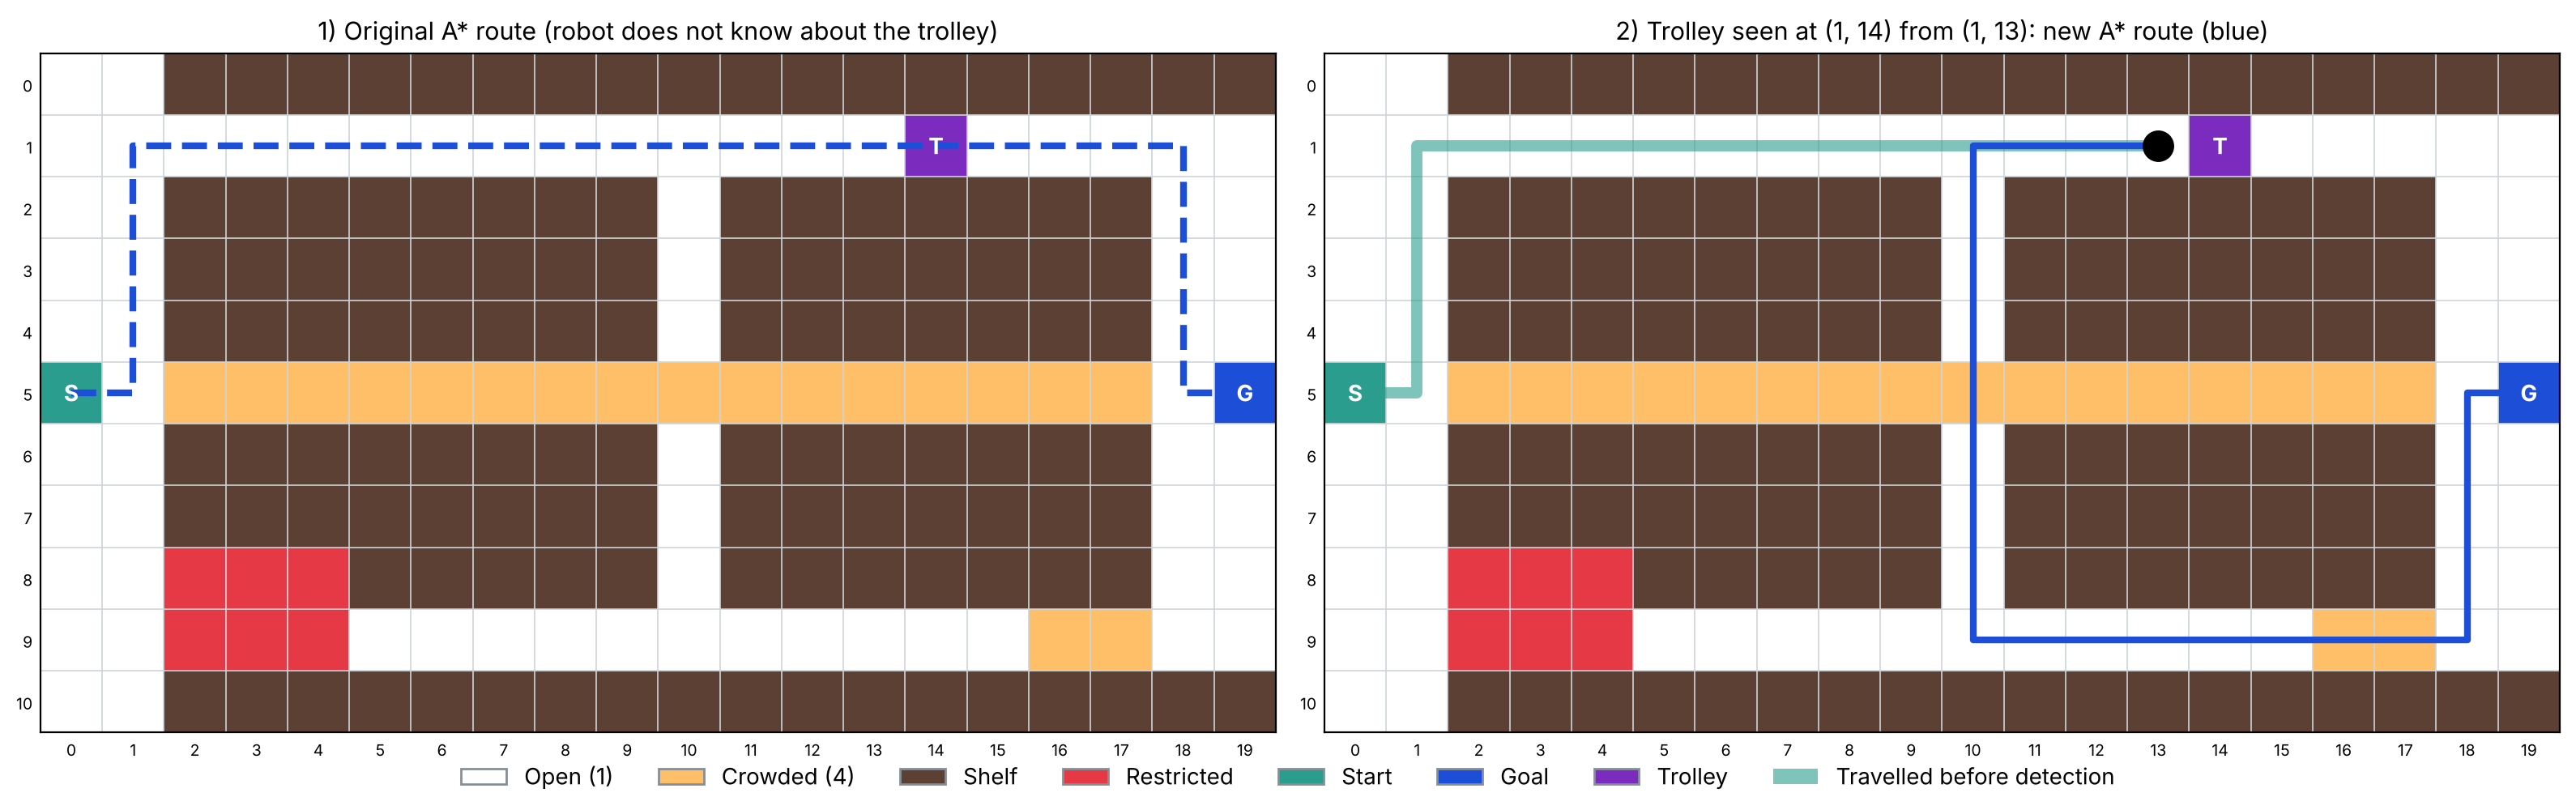

In [10]:
initial = results['A*']['path']
trolley = initial[2 * len(initial) // 3]
real_A = [row[:] for row in GRID]
real_A[trolley[0]][trolley[1]] = 'T'
print('Trolley placed at', trolley, '(on the initial A* route, not on the robot map)\n')

t0 = time.perf_counter()
log_A, reached_A = run_robot(real_A, GRID)
time_A = (time.perf_counter() - t0) * 1000
report(log_A, reached_A, real_A)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
draw(axes[0], real_A, path=initial, title='1) Original A* route (robot does not know about the trolley)', style='--')
seen_at, found = log_A['detections'][0]
before = log_A['walked'][:log_A['walked'].index(seen_at) + 1]
draw(axes[1], real_A, path=log_A['plans'][-1], robot=seen_at,
     title=f'2) Trolley seen at {found} from {seen_at}: new A* route (blue)')
br, bc = zip(*before)
axes[1].plot(bc, br, color='#2a9d8f', linewidth=5, alpha=0.6, zorder=2)
fig.legend(handles=LEGEND + [Patch(facecolor='#2a9d8f', alpha=0.6, label='Travelled before detection')],
           loc='lower center', ncol=8, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
show(fig, '3_trolley_replan')

### Animation of Scenario A
The picture shows the **robot's own map**. Black dot = robot, blue line = its current plan, green trail = cells already travelled, dashed purple `?` = a trolley the robot has not seen yet. Watch it stop in front of the trolley, add it to its map (solid purple **T**) and take the new route.

In [11]:
def animate(real_grid, log, name):
    fig, ax = plt.subplots(figsize=(10, 5.5), dpi=72)
    def frame(k):
        ax.clear()
        pos, plan, known, note, n_walked = log['frames'][k]
        draw(ax, known, path=plan, robot=pos, title=f'Step {k}: {note}  |  replans so far: '
             f"{sum(1 for f in log['frames'][:k + 1] if 'Trolley' in f[3])}")
        for r in range(ROWS):                          # trolleys the robot has not seen yet: dashed box with '?'
            for c in range(COLS):
                if real_grid[r][c] == 'T' and known[r][c] != 'T':
                    ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fill=False, edgecolor='#7b2cbf',
                                               linewidth=2.5, linestyle='--', zorder=4))
                    ax.text(c, r, '?', ha='center', va='center', color='#7b2cbf', fontweight='bold', zorder=5)
        walked = log['walked'][:n_walked]
        if len(walked) > 1:
            wr, wc = zip(*walked)
            ax.plot(wc, wr, color='#2a9d8f', linewidth=5, alpha=0.5, zorder=2)
    anim = animation.FuncAnimation(fig, frame, frames=len(log['frames']), interval=350)
    anim.save(f'outputs/{name}.gif', writer=animation.PillowWriter(fps=3))
    plt.close()
    if IN_NOTEBOOK:
        display(HTML(anim.to_jshtml()))

animate(real_A, log_A, '4_trolley_animation')

### Scenario B – trolleys block every aisle (no alternative)
Three hidden trolleys stand in the top, middle and bottom aisles at column 12. The robot discovers them one at a time, replans each time, and finally reports that no route exists.

Hidden trolleys at (1, 12), (5, 12) and (9, 12): top, middle and bottom aisles

  Trolley detected at (1, 12) while at (1, 11) -> replan #1 -> new route of 22 moves
  Trolley detected at (9, 12) while at (9, 11) -> replan #2 -> new route of 14 moves
  Trolley detected at (5, 12) while at (5, 11) -> replan #3 -> NO ALTERNATIVE ROUTE
  Goal reached     : False
  Moves travelled  : 31
  Cost travelled   : 40
  Replans          : 3
  Nodes expanded   : 183 (all A* searches)


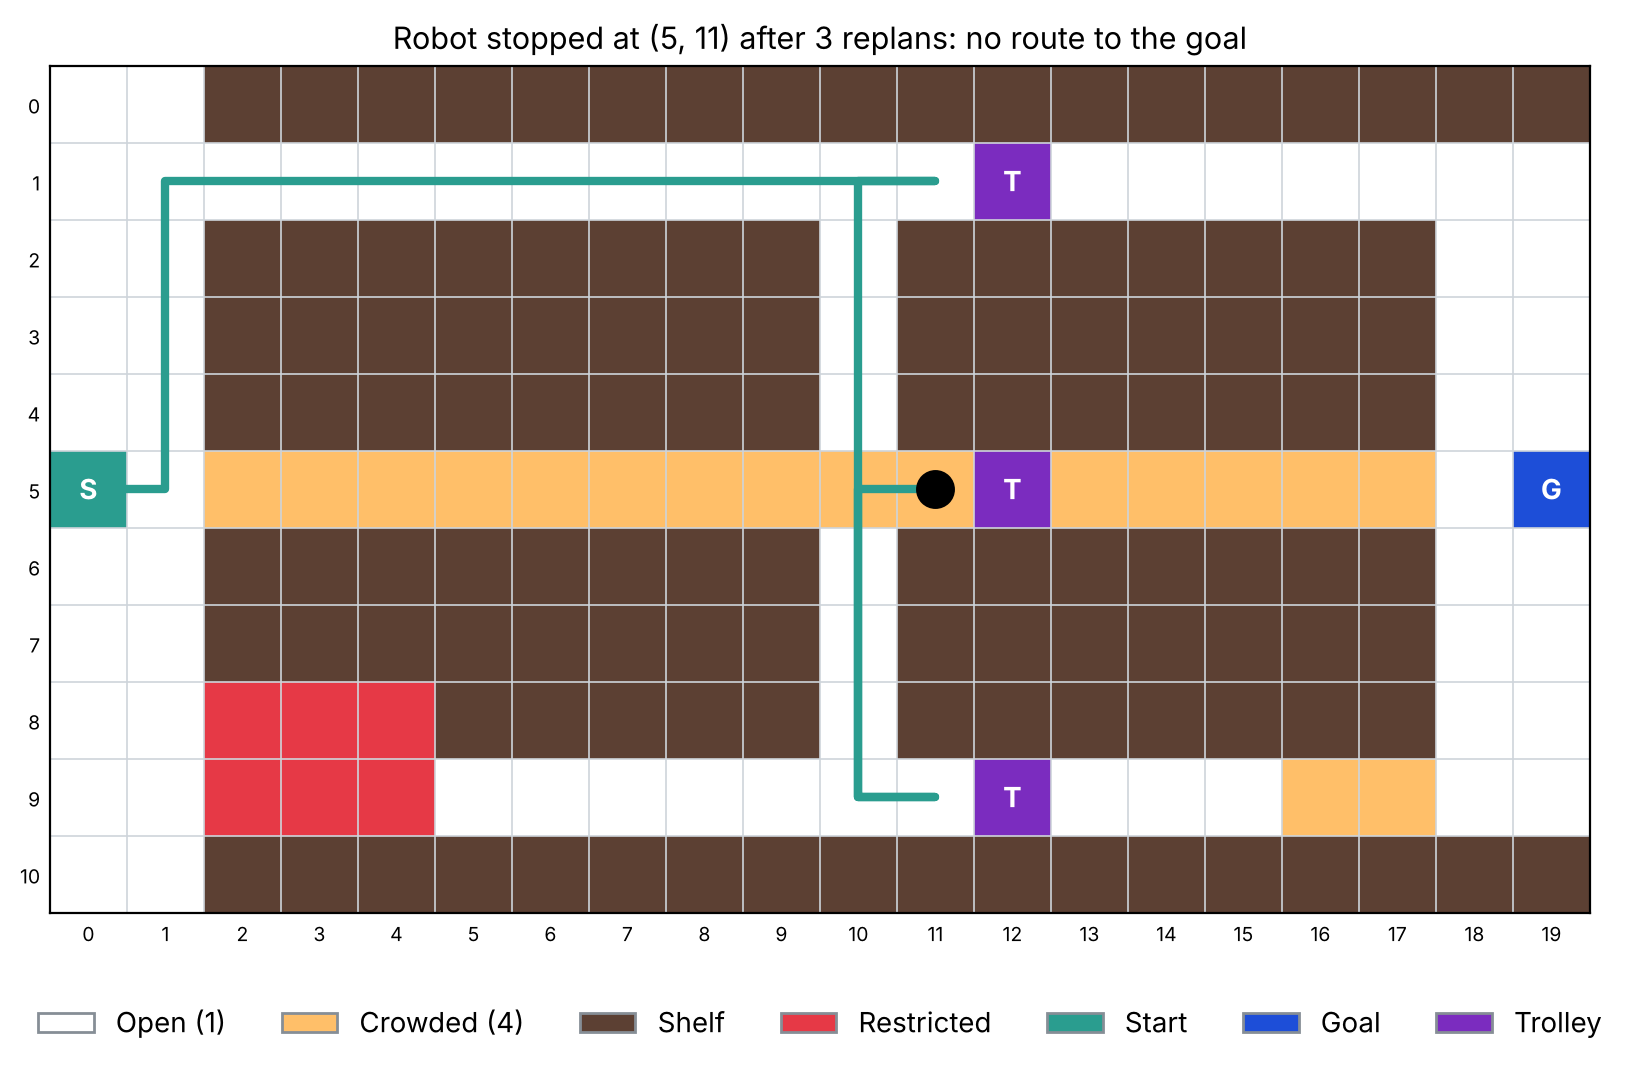

In [12]:
real_B = [row[:] for row in GRID]
for r in (1, 5, 9):
    real_B[r][12] = 'T'
print('Hidden trolleys at (1, 12), (5, 12) and (9, 12): top, middle and bottom aisles\n')

t0 = time.perf_counter()
log_B, reached_B = run_robot(real_B, GRID)
time_B = (time.perf_counter() - t0) * 1000
report(log_B, reached_B, real_B)

fig, ax = plt.subplots(figsize=(11, 5.5))
draw(ax, real_B, path=log_B['walked'], robot=log_B['walked'][-1], path_color='#2a9d8f',
     title=f"Robot stopped at {log_B['walked'][-1]} after {log_B['replans']} replans: no route to the goal")
ax.legend(handles=LEGEND, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=7, frameon=False)
show(fig, '5_no_alternative')
animate(real_B, log_B, '6_no_alternative_animation')

## 6. Task 5 – Performance evaluation

In [13]:
print('Search algorithms on the warehouse grid')
print(f"{'Algorithm':10}{'Goal reached':>14}{'Moves':>8}{'Cost':>7}{'Nodes expanded':>17}{'Time (ms)':>12}")
for a, r in results.items():
    print(f"{a:10}{str(r['found']):>14}{r['moves']:>8}{r['cost']:>7}{r['expanded']:>17}{r['time_ms']:>12.3f}")

print('\nTrolley experiments (A* with replanning)')
print(f"{'Scenario':28}{'Goal reached':>14}{'Moves':>8}{'Cost':>7}{'Nodes expanded':>17}{'Replans':>9}{'Time (ms)':>12}")
for name, log, ok, grid, t in [('A: one trolley', log_A, reached_A, real_A, time_A),
                               ('B: every aisle blocked', log_B, reached_B, real_B, time_B)]:
    print(f"{name:28}{str(ok):>14}{len(log['walked']) - 1:>8}{path_cost(grid, log['walked']):>7}"
          f"{log['nodes']:>17}{log['replans']:>9}{t:>12.3f}")

Search algorithms on the warehouse grid
Algorithm   Goal reached   Moves   Cost   Nodes expanded   Time (ms)
BFS                 True      19     67               73       0.246
DFS                 True      45     72               80       0.163
Greedy              True      19     67               20       0.058
A*                  True      27     27               49       0.179

Trolley experiments (A* with replanning)
Scenario                      Goal reached   Moves   Cost   Nodes expanded  Replans   Time (ms)
A: one trolley                        True      41     50               95        1       0.435
B: every aisle blocked               False      31     40              183        3       1.283


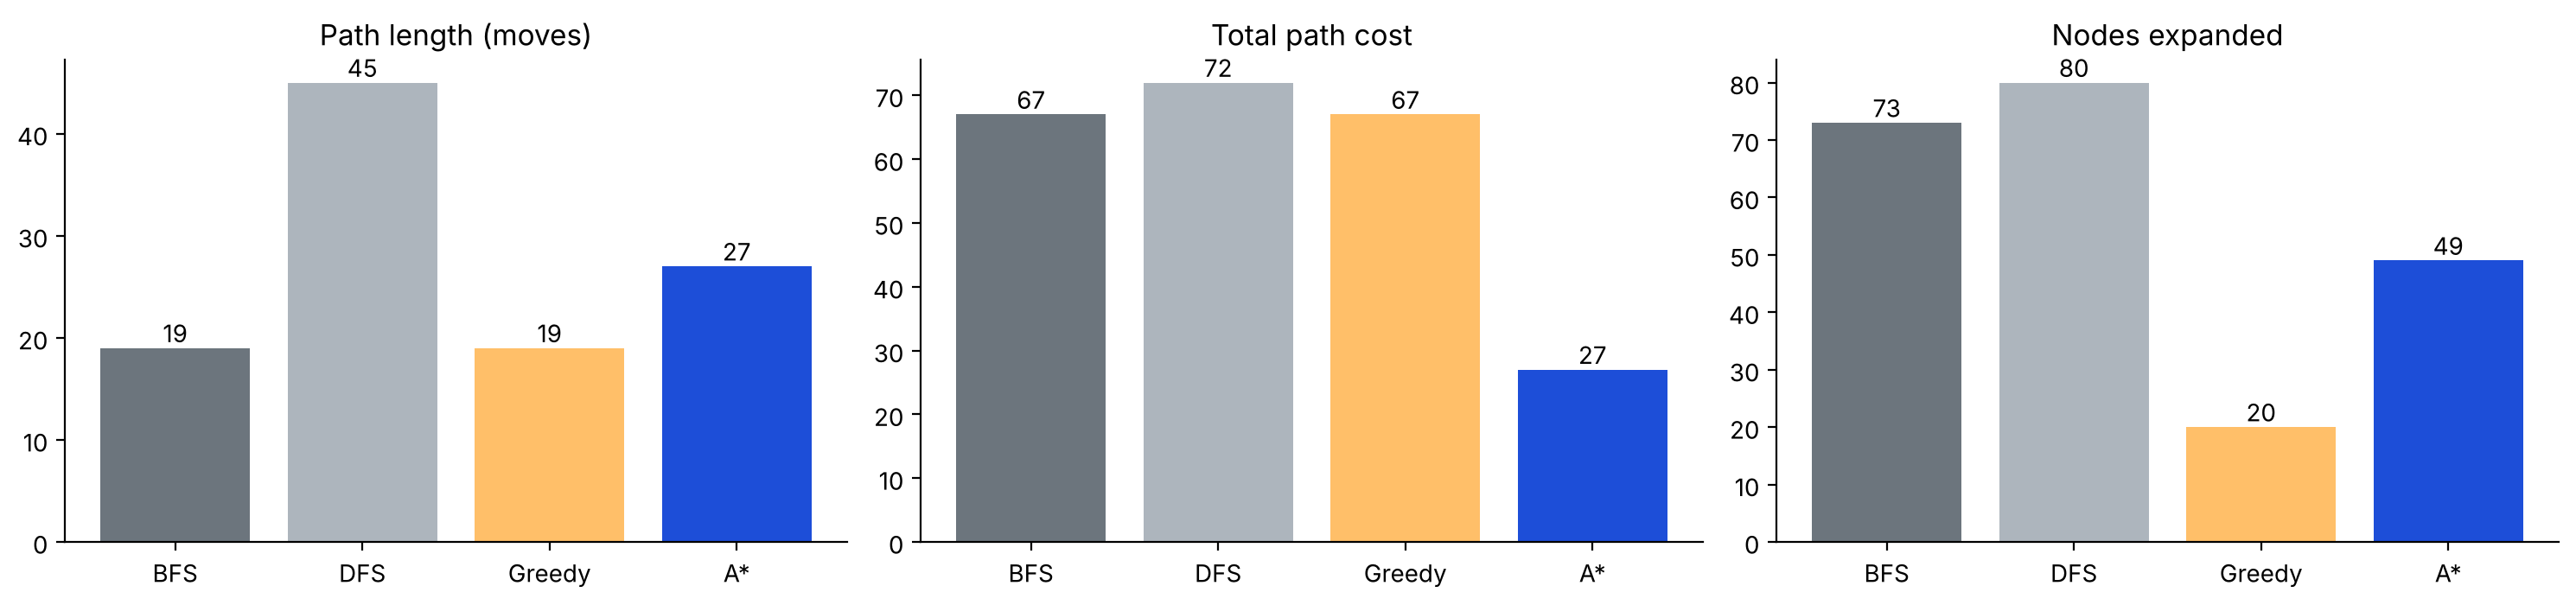

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
colors = ['#6c757d', '#adb5bd', '#ffbf69', '#1d4ed8']
for ax, key, label in zip(axes, ['moves', 'cost', 'expanded'], ['Path length (moves)', 'Total path cost', 'Nodes expanded']):
    vals = [results[a][key] for a in ALGORITHMS]
    bars = ax.bar(ALGORITHMS, vals, color=colors)
    ax.bar_label(bars)
    ax.set_title(label)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
show(fig, '7_comparison_chart')

## 7. Findings
- **The shortest route did not have the lowest cost.** BFS returned the 19-move route through the crowded middle aisle (cost 67), because it minimises moves and ignores cell costs. A\* returned a 27-move route through the open top aisle with cost 27, the lowest cost possible.
- **Greedy** followed the Manhattan distance straight into the crowded aisle. It expanded very few nodes but ignored the cost already paid, so its route cost 67.
- **DFS** went deep in the first direction it tried (Up) and wandered around the warehouse: a long, costly route. It is neither shortest nor cheapest.
- **A\*** expanded more nodes than Greedy but is the only algorithm that guarantees the lowest-cost route, because Manhattan distance never overestimates the remaining cost.
- **Replanning:** with one hidden trolley the robot stopped in front of it, updated its map and reached the goal after 1 replan. When every aisle was blocked it replanned after each discovery and correctly reported that no alternative route exists.